# Waveguide RK4 convergence

By default, Run All plots the existing convergence CSV files. Set RUN_SIMULATIONS=True to recompute the scan (potentially long). Coarse time steps deliberately include unstable RK4 runs. The initial packet position is x_init=-12.5. Evolution runs from 0 to T.

**Setup:** from the repository root, run `conda env create -f environment.yml` then `conda activate single-photon-renorm`, then `jupyter lab`. Select that Python environment as the kernel. The first cell also supports running directly from the checkout.

**How to use:** run cells from top to bottom. Parameters are grouped before the simulation or plotting cells. Figures display inline; `SAVE_FIGURES=False` prevents overwriting exported PDFs. Units: ħ = c = 1. See `guide_utilisation.pdf` at the repository root for notation and the calibration workflow.


<h1> Experiment reflection against number of RK4 steps </h1>

In [15]:
RUN_SIMULATIONS = False  # True recomputes the selected scan and writes its CSVs.
SAVE_FIGURES = True  # Set True to export the figures to results/fig.

# Run from the repository root or any of its subdirectories.
import sys
from pathlib import Path
project_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "src" / "experiment.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open Jupyter inside the single_photon_code checkout; see README.md.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
benchmark_root = project_root / "waveguide_model"
setup_root = project_root / "2d_setup"

#General imports
resol = 300
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Lines / markers
    "lines.linewidth": 1.0,
    "lines.markersize": 4,

})

import numpy as np
pi = np.pi


#Local imports
from waveguide_model.scripts_experiments.reflection_vs_RKstep import run_reflection_vs_RKstep

from waveguide_model.bare_param import get_bare_parameters


<h2> Execute the experiment </h2>

Prepare the experiment

In [16]:
#Time evolution
T = 50
nb_pts_steps = 50
N_step_tab = np.unique(np.logspace(1, 4, nb_pts_steps).astype(int))
dt_tab = T / N_step_tab

#Physical parameters
Omega_A = 10*pi
gamma_A = pi
L = 100
param_cavity_physical = {'Omega_A': Omega_A, 'gamma_A': gamma_A, 'L': L}

p0_tab = [10*pi, 9.75*pi, 9.5*pi]
cutoffs_tab = [(10*pi - k*pi, 10*pi + k*pi) for k in range(1,11)]

#Incoming photon parameters
param_photon_bis = {'sigma_p': 0.05*np.pi, 'x_init': -12.5}


Run the loop

In [17]:
if RUN_SIMULATIONS:
    correction = True

    for (p0_value, i) in zip(p0_tab, range(len(p0_tab))):
        for (cutoff, j) in zip(cutoffs_tab, range(len(cutoffs_tab))):
            index_p0, index_cutoff = i+1, j+1

            print(f"Running for p_0 = {p0_value:.2f} and cutoff = {cutoff}")

            param_photon = dict(param_photon_bis, p_init=p0_value)
            cutoffs = {"Omega_min": cutoff[0], "Omega_max": cutoff[1]}
            Omega_0, gamma_0 = get_bare_parameters(Omega_A, gamma_A, cutoffs, correction=correction)
            param_cavity = {'Omega_0': Omega_0, 'gamma_0': gamma_0, 'L': L}

            _= run_reflection_vs_RKstep(param_photon, param_cavity, T, dt_tab, cutoffs,
                                        index_experiment=index_cutoff, index_p0=index_p0)
else:
    print("Using the existing CSV results; scan skipped.")


Using the existing CSV results; scan skipped.


## Plot the results

Run the imports and parameter cells, then the desired figure cell. Existing CSV files are sufficient; rerunning the simulations is optional. Each plotting cell loads its own data and exports one PDF.

### RK4 convergence — experiments 1 and 3

The combined figure follows the reference paper layout, with individual axis labels and a shared legend below the plots. Insert it at full text width. The original 5% convergence criterion and shaded bands are preserved.

Layout reference: [coincidence_vs_frequency_results.ipynb](https://github.com/rpiron/calibration_twophoton_waveguideQED/blob/main/notebooks/coincidence_vs_frequency_results.ipynb).

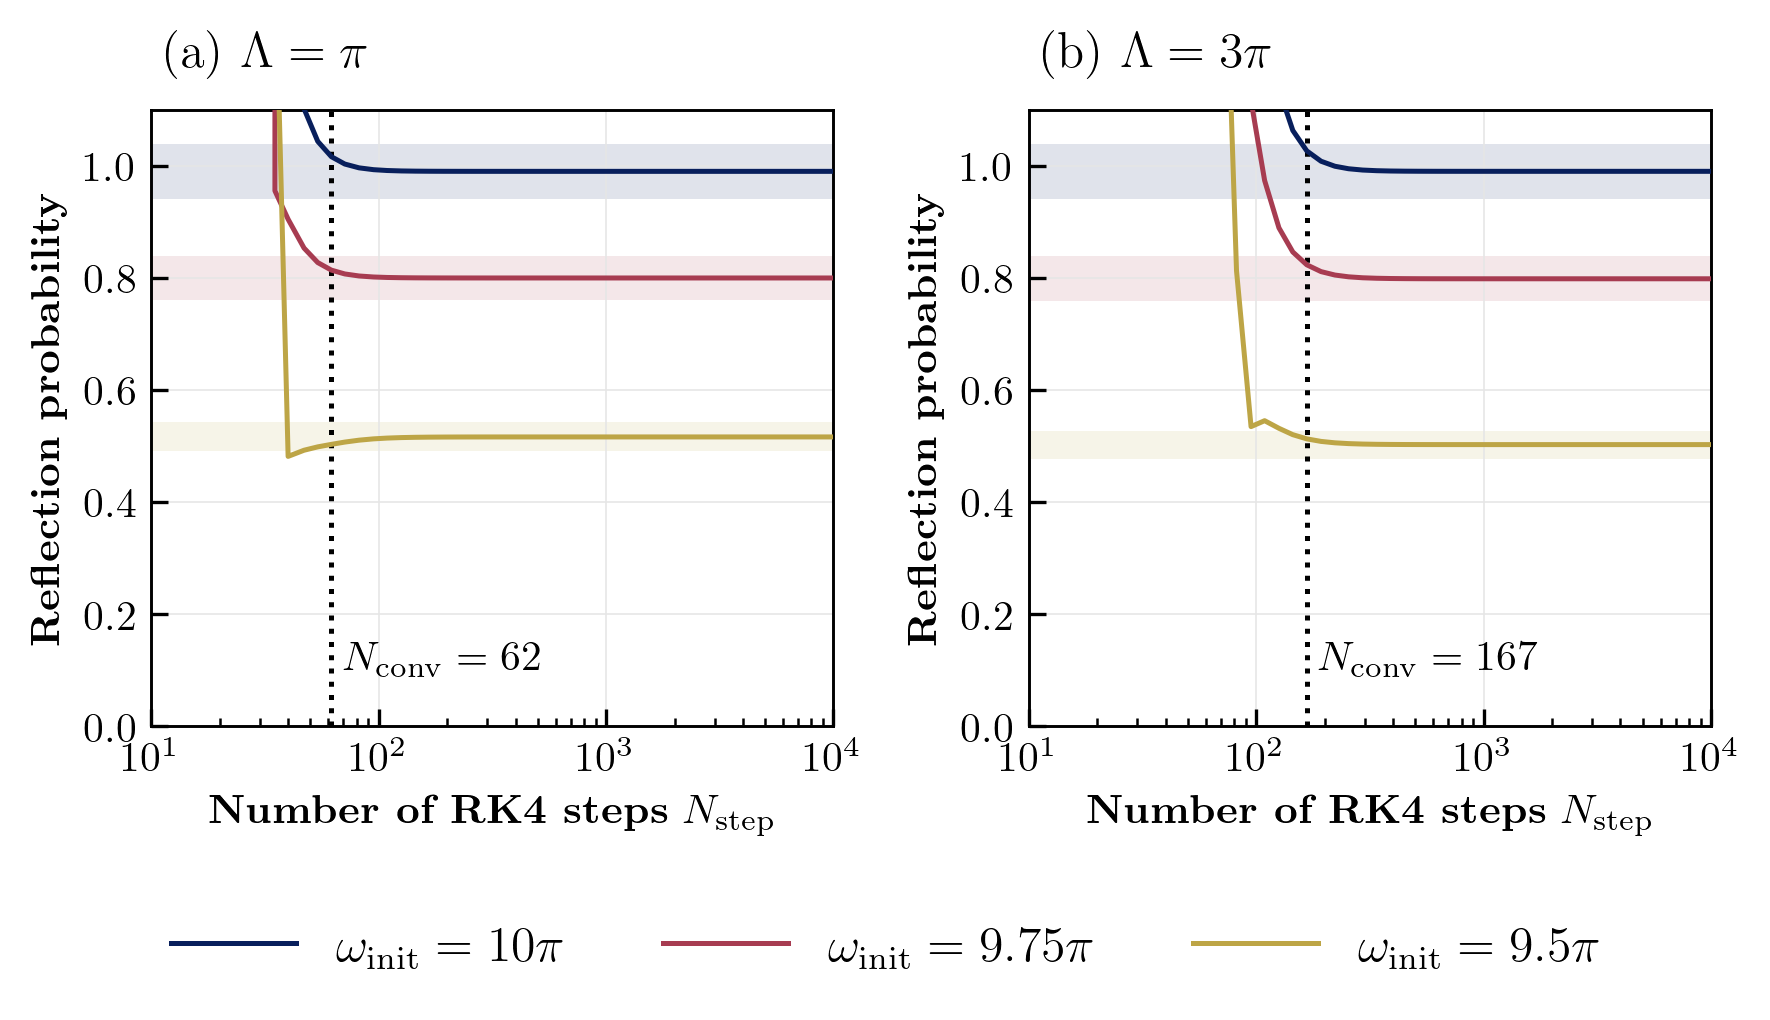

In [18]:
# Experiments 1 and 3: symmetric windows with Lambda = pi and 3 pi.

CSV_DIR = project_root / "waveguide_model/results/csv_files/reflection_vs_RKstep"
FIG_DIR = project_root / "waveguide_model/results/fig/reflection_vs_RKstep"
FIG_DIR.mkdir(parents=True, exist_ok=True)

colors = ['#081f5c', '#a73c51', '#bda546']
line_styles = ['-', '-', '-']
labels = [r'$\omega_{\mathrm{init}} = 10\pi$',
          r'$\omega_{\mathrm{init}} = 9.75\pi$',
          r'$\omega_{\mathrm{init}} = 9.5\pi$']

# Layout of the reference paper: individual axes, one-line panel labels, legend below.
# Font sizes account for reduction to approximately 18 cm in the article.
fig, axes = plt.subplots(1, 2, figsize=(6, 3), dpi=resol)

for panel_index, (ax, index_experiment) in enumerate(zip(axes, [1, 3])):
    convergence_steps = []
    for index_p0, (color, line_style, label) in enumerate(zip(colors, line_styles, labels), start=1):
        df = pd.read_csv(CSV_DIR / f"reflection_vs_RKstep_omegap_{index_p0}_xp{index_experiment}.csv")
        # Read the actual time steps from each CSV instead of reconstructing its sampling.
        N_steps = np.rint(T / df['dt'].to_numpy()).astype(int)
        y = df['final_reflection'].to_numpy()
        ax.plot(N_steps, y, color=color, ls=line_style, lw=1.2, label=label, zorder=3)
        # Preserve the original band: +/-5% of the mean of the final 20 samples.
        y_inf = np.mean(y[-20:])
        ax.fill_between(N_steps, 0.95*y_inf, 1.05*y_inf, color=color, alpha=0.12, linewidth=0, zorder=1)
        # Preserve the original convergence criterion: first point within 5% of the last sample.
        conv_index = np.flatnonzero(np.abs(y - y[-1]) < 0.05*y[-1])[0]
        convergence_steps.append(N_steps[conv_index])

    N_step_convergence = max(convergence_steps)
    ax.axvline(N_step_convergence, color='black', ls=':', lw=1.2, zorder=2)
    ax.text(N_step_convergence*1.12, 0.10, rf'$N_{{\rm conv}} = {N_step_convergence}$', fontsize=10)
    bandwidth = (cutoffs_tab[index_experiment - 1][1] - cutoffs_tab[index_experiment - 1][0])/2
    bandwidth_label = r'\pi' if np.isclose(bandwidth/pi, 1) else rf'{bandwidth/pi:g}\pi'
    ax.text(0.02, 1.05, rf'({"ab"[panel_index]}) $\Lambda = {bandwidth_label}$',
            transform=ax.transAxes, fontsize=12, va='bottom')
    ax.set_xscale('log')
    ax.set_xlim(1e1, 1e4)
    ax.set_xticks([1e1, 1e2, 1e3, 1e4])
    ax.set_ylim(0, 1.1)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.grid(color='0.9', linestyle='-', linewidth=0.4)
    ax.set_xlabel(r'\textbf{Number of RK4 steps} $N_{\rm step}$', fontsize=10)
    ax.set_ylabel(r'\textbf{Reflection probability}', fontsize=10)
    ax.tick_params(axis='both', which='major', length=4, width=0.8, labelsize=10)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0),
           ncol=3, fontsize=12, frameon=False, handlelength=2.5, columnspacing=2)
fig.tight_layout()
if SAVE_FIGURES:
    fig.savefig(FIG_DIR / 'experiment_convergence_RKstep.pdf', dpi=resol, bbox_inches='tight', pad_inches=0.2)
plt.show()


### Minimal number of steps for convergence against bandwidth

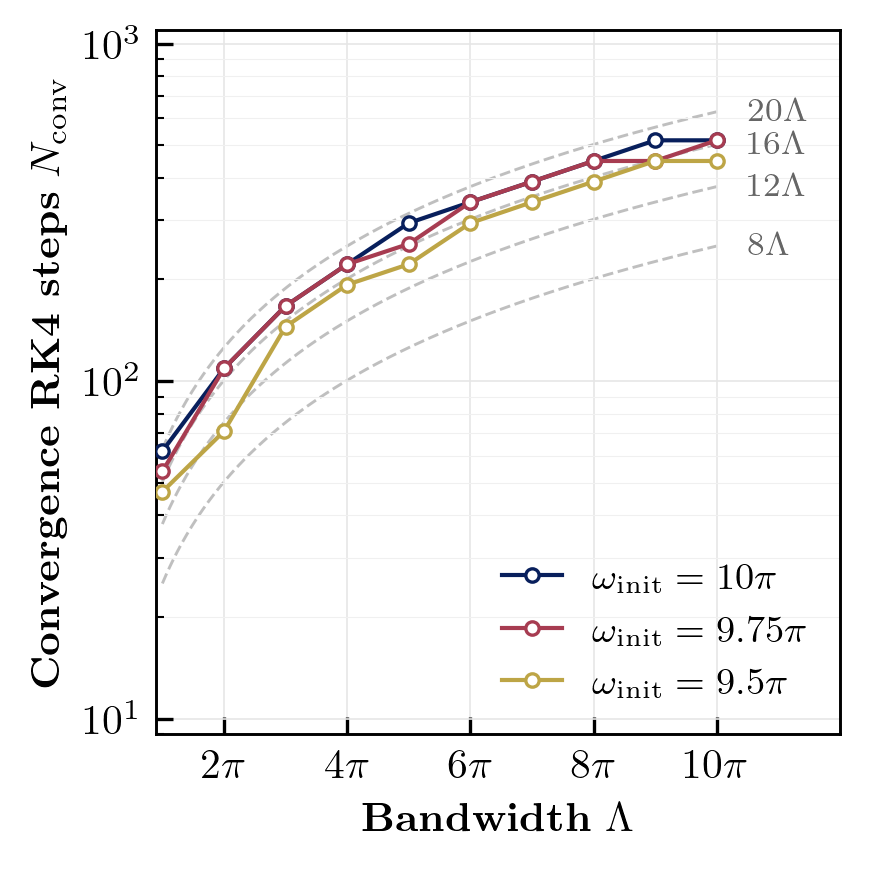

In [19]:
N_step_convergence_several_curves = []
bandwidth_tab = (np.array(cutoffs_tab)[:,1] - np.array(cutoffs_tab)[:,0])/2

for index_p0 in range(1, len(p0_tab)+1):

    N_step_convergence_tab = []

    T = 50  
    nb_pts_steps = 50
    N_step_tab = np.unique(np.logspace(1, 4, nb_pts_steps).astype(int))
    dt_tab = T / N_step_tab

    for i in range(len(cutoffs_tab)):
        file_data = project_root / f"waveguide_model/results/csv_files/reflection_vs_RKstep/reflection_vs_RKstep_omegap_{index_p0}_xp{i+1}.csv"
        df = pd.read_csv(file_data)
        #Recover the minimal step required to reach convergence for this curve
        conv_index = np.where(np.abs(df['final_reflection'] - df['final_reflection'].iloc[-1]) < 0.05 * df['final_reflection'].iloc[-1])[0][0]
        dt_convergence = df['dt'].values[conv_index]

        N_step_convergence = int(round(T / dt_convergence))
        N_step_convergence_tab.append(N_step_convergence)
    
    N_step_convergence_several_curves.append(N_step_convergence_tab)

colors = ['#081f5c', '#a73c51', '#bda546']
labels = [
    r'$\omega_{\mathrm{init}} = 10\pi$',
    r'$\omega_{\mathrm{init}} = 9.75\pi$',
    r'$\omega_{\mathrm{init}} = 9.5\pi$'
]

fig, ax = plt.subplots(figsize=(3, 3), dpi=300)

# Reference guides for N_conv proportional to the simulated bandwidth.
scaling_factors = [8, 12, 16, 20]
bandwidth_guide = np.linspace(bandwidth_tab.min(), bandwidth_tab.max(), 300)
n_conv_values = np.asarray(N_step_convergence_several_curves, dtype=float)

for f in scaling_factors:
    y_guide = f * bandwidth_guide
    ax.plot(
        bandwidth_guide,
        y_guide,
        '--',
        color='0.55',
        alpha=0.55,
        linewidth=0.7,
        zorder=1
    )
    ax.text(
        bandwidth_guide[-1] * 1.05,
        y_guide[-1],
        rf'${f}\Lambda$',
        color='0.4',
        fontsize=8,
        va='center',
        ha='left'
    )

for i, (c, lab) in enumerate(zip(colors, labels)):
    N_step_convergence_tab = N_step_convergence_several_curves[i]
    ax.plot(
        bandwidth_tab,
        N_step_convergence_tab,
        'o-',
        color=c,
        markerfacecolor='white',
        markeredgewidth=0.8,
        markersize=3.2,
        linewidth=1.0,
        label=lab,
        zorder=3
    )

#ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(bandwidth_tab.min() * 0.9, bandwidth_tab.max() * 1.2)
ax.set_ylim(0.9*1e1, 1.1*1e3)
#ax.set_ylim(
#    min(n_conv_values.min(), scaling_factors[0] * bandwidth_tab.min()) * 0.75,
#    max(n_conv_values.max(), scaling_factors[-1] * bandwidth_tab.max()) * 1.25)

ax.set_xticks([2*pi, 4*pi, 6*pi, 8*pi, 10*pi],
              [r'$2\pi$', r'$4\pi$', r'$6\pi$', r'$8\pi$', r'$10\pi$'])

ax.set_xlabel(r'\textbf{Bandwidth} $\Lambda$', fontsize=10)
ax.set_ylabel(r'\textbf{Convergence RK4 steps} $N_{\rm conv}$', fontsize=10)
ax.grid(color='0.9', linestyle='-', linewidth=0.4, which='major')
ax.grid(color='0.94', linestyle='-', linewidth=0.25, which='minor')
ax.tick_params(axis='both', which='major', length=4, width=0.8, labelsize=10)
ax.tick_params(axis='both', which='minor', length=2, width=0.5)
ax.legend(prop={'size': 9}, loc='lower right', frameon=False, handlelength=1.6)

plt.tight_layout()
if SAVE_FIGURES:
    plt.savefig(project_root / "waveguide_model/results/fig/reflection_vs_RKstep/Nconv_vs_bandwidth.pdf", dpi=resol)
plt.show()
